# Concentration GUI example

Click the wells in a **popup window**, then this notebook analyzes them.
Plots and images stay **inside the notebook**.

**How to run**

1. Run the cells from top to bottom.
2. In *Choose your image*, either keep the example image or uncomment `IMAGE_PATH`.
3. When the well-selection window opens, click the wells, then press **Enter**.
4. The remaining cells show plots here. If saving is on, files go in a results folder.


## 1. Setup

This cell loads QAL and keeps later plots inside the notebook.


In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qal import WellAnalyzer, WellPlotter, select_concentration_grid
from qal.data import cn_sample_1, get_concentration_target_preset
from qal.util import load_grayscale_image


## 2. Choose your image

`IMAGE_PATH = cn_sample_1()` loads the built-in example image.

To use your own image, comment out that line and set `IMAGE_PATH` to a
TIFF, BMP, PNG, or JPEG file path. Leave only one option active.
The relative file path works from this notebook's folder in a GitHub checkout or download.

`None` raises an error because no image has been supplied.

**Quantitative image input:** this example passes the input through
`load_grayscale_image` before analysis. Native 2-D grayscale values and dtype
are preserved without rescaling. RGB/RGBA inputs use the first channel;
convert color images explicitly before analysis if another conversion is needed.


In [ ]:
# Images are loaded and converted to grayscale with load_grayscale_image.
# Already-grayscale images remain unchanged: stored values and dtype are preserved.
# RGB/RGBA inputs use the first channel; convert color images explicitly if needed.
# Choose one option; leave the others commented out.
# Uncomment the next line and put the path to your image:
# IMAGE_PATH = "/path/to/your/image.tiff"

# Example using a file that ships with QAL:
# Run from this example's directory in a GitHub checkout or download.
# IMAGE_PATH = "../../data/concentration_targets/cn_sample_1.tiff"

# Selecting the built-in example image:
IMAGE_PATH = cn_sample_1()


## 3. Saving plots and data

These are the knobs that control whether files are written, and what they are
called. When `SAVE_RESULTS` is `True`:

- If you set `IMAGE_PATH` to a file path, files go next to that image in `<image_name>_results/`
- If you use the built-in image, files go next to this notebook in `cn_sample_1_results/`


In [ ]:
# Set this to True to write plots and CSV files.
SAVE_RESULTS = True

# File names inside the results folder (used only when SAVE_RESULTS is True):
SAVE_ROI_PLOT = "roi.png"
SAVE_CONCENTRATION_PLOT = "concentration.png"
SAVE_STATS_CSV = "stats.csv"


## 4. Analysis options

You can usually leave these as they are.

Click order for the first three wells (left to right along the top row):

`1000 nM` → `300 nM` → `100 nM`


In [14]:
# Product type: "icg", "q800", or "q700"
TARGET_TAG = "icg"

# How wells are selected. Uncomment one:
# MODE = "automatic_refinement"
MODE = "manual_live_preview"
# MODE = "manual_coordinates"

# How many wells to click (3 is enough; they must be left-to-right, top-to-bottom).
ANCHOR_COUNT = 3

# Circle size in pixels. None = estimate from well spacing.
MANUAL_ROI_DIAMETER = None

# Fraction of each well used for intensity (0.5 is recommended).
REGION_OF_WELL_TO_ANALYZE = 0.5


## 5. Load the image


Target: ICG-equivalent concentration sensitivity target


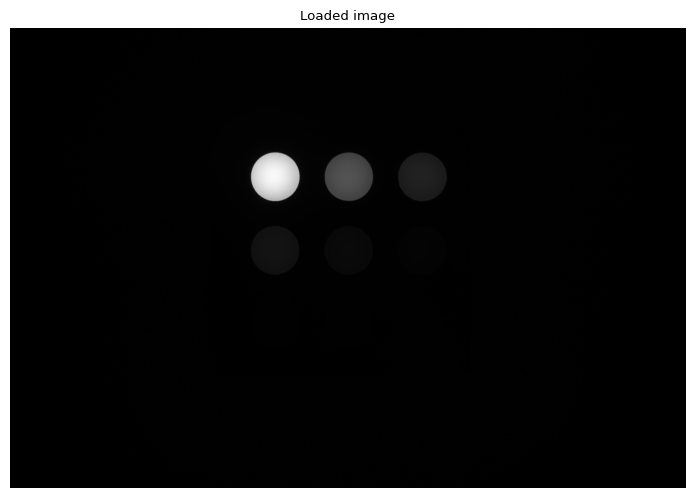

In [15]:
if IMAGE_PATH is None:
    raise ValueError("No image has been supplied. Set IMAGE_PATH to an image file path or a built-in example call.")

if isinstance(IMAGE_PATH, np.ndarray):
    image = load_grayscale_image(IMAGE_PATH)
    results_dir = Path("cn_sample_1_results")
else:
    image = load_grayscale_image(IMAGE_PATH)
    image_file = Path(IMAGE_PATH).expanduser()
    results_dir = image_file.parent / f"{image_file.stem}_results"

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    print(f"Results folder: {results_dir.resolve()}")
else:
    results_dir = None

target = get_concentration_target_preset(TARGET_TAG)
well_ids = target["well_ids"]
print(f"Target: {target['display_name']}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(image, cmap="gray")
ax.set_title("Loaded image")
ax.axis("off")
plt.show()


## 6. Select wells (popup window)

This cell opens a window. Click the wells, then press **Enter**. Drag a `+` to move it.

Later plots stay in this notebook.


In [16]:
wells = select_concentration_grid(
    image,
    well_ids,
    mode=MODE,
    anchor_count=ANCHOR_COUNT,
    manual_roi_diameter=MANUAL_ROI_DIAMETER,
)


Mode: manual_live_preview
Select the first 3 wells in row-major order (left-to-right, then top-to-bottom):
  1. 1000 nM
  2. 300 nM
  3. 100 nM
Your clicked coordinates will be used without auto-detection.
Drag any marker to align the live 3x3 circle overlay.
Press Enter/Return after all selections.
Opening a window. Click the wells, then press Enter or close the window.

Selected anchor centroids:
             x           y  ROI Diameter  ROI Radius     well
0  1620.780141  929.391334    273.374938  136.687469  1000 nM
1  2089.349035  924.526723    273.374938  136.687469   300 nM
2  2544.958463  928.281122    273.374938  136.687469   100 nM

Completed concentration grid:
             x            y  ROI Diameter  ROI Radius     well   value
0  1622.940052   927.954832    273.374938  136.687469  1000 nM  1000.0
1  2085.029213   927.399726    273.374938  136.687469   300 nM   300.0
2  2547.118374   926.844620    273.374938  136.687469   100 nM   100.0
3  1623.495158  1390.043993    273.

## 7. Analyze the selected wells


In [17]:
if not isinstance(wells, pd.DataFrame):
    raise RuntimeError(
        "No well table yet. Finish the popup with Enter, then rerun "
        "the select-wells cell."
    )

analyzer = WellAnalyzer(image, wells)
stats = analyzer.get_stats(region_of_well_to_analyze=REGION_OF_WELL_TO_ANALYZE)
stats


,x,y,ROI Diameter,ROI Radius,well,value,Analyzed ROI Diameter,mean intensity,standard deviation,min intensity,max intensity,mean intensity baselined,mean intensity normalized,standard deviation normalized,CNR
0,1622.940052,927.954832,273.374938,136.687469,1000 nM,1000.0,136.687469,59967.828077,1512.718699,54704.0,63620.0,59089.003602,1.000000,0.036222,1285.746964
1,2085.029213,927.399726,273.374938,136.687469,300 nM,300.0,136.687469,20488.636512,551.388274,18440.0,22360.0,19609.812037,0.331869,0.012646,426.699635
2,2547.118374,926.844620,273.374938,136.687469,100 nM,100.0,136.687469,8588.872242,320.518678,7428.0,9556.0,7710.047767,0.130482,0.006418,167.766757
3,1623.495158,1390.043993,273.374938,136.687469,60 nM,60.0,136.687469,5362.511926,204.637018,4644.0,6104.0,4483.687451,0.075880,0.004047,97.562781
4,2085.584319,1389.488887,273.374938,136.687469,30 nM,30.0,136.687469,3044.486601,133.910174,2540.0,3596.0,2165.662125,0.036651,0.002573,47.123717
5,2547.673479,1388.933781,273.374938,136.687469,10 nM,10.0,136.687469,1580.992028,79.853550,1252.0,1948.0,702.167553,0.011883,0.001589,15.278812
6,1624.050264,1852.133153,273.374938,136.687469,3 nM,3.0,136.687469,1046.390573,55.352000,844.0,1264.0,167.566098,0.002836,0.001220,3.646154
7,2086.139424,1851.578047,273.374938,136.687469,1 nM,1.0,136.687469,925.056449,47.519351,752.0,1112.0,46.231974,0.000782,0.001119,1.005984
8,2548.228585,1851.022942,273.374938,136.687469,Control,0.0,136.687469,878.824475,45.956946,696.0,1060.0,0.000000,0.000000,NaN,0.000000


## 8. Show the regions of interest


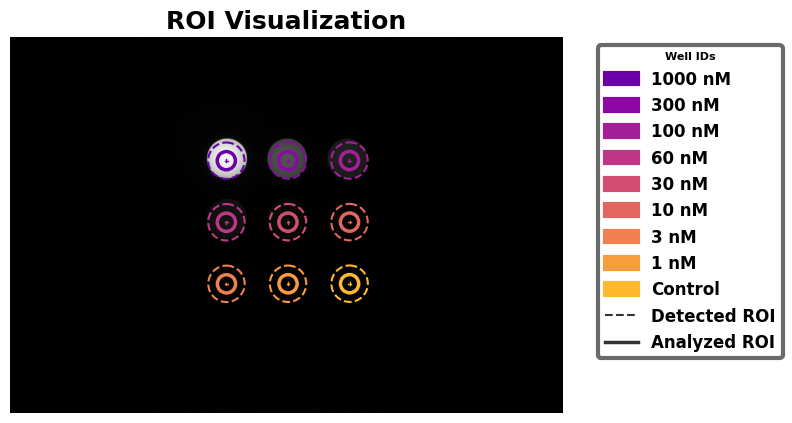

In [18]:
plotter = WellPlotter(stats, image=image)
roi_path = results_dir / SAVE_ROI_PLOT if results_dir is not None else None
plotter.visualize_roi(save_plot=roi_path)
if results_dir is not None:
    print(f"Saved {roi_path}")


## 9. Plot concentration vs intensity


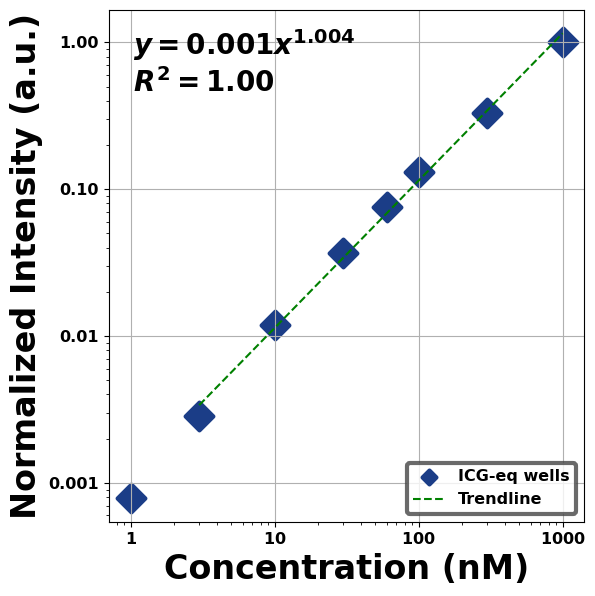

In [19]:
plotter.plot(
    graph_type="concentration",
    col_to_plot="mean intensity normalized",
    fluorophore_label=target.get("fluorophore_label", "ICG-eq"),
    trendline_lib="statsmodels",
    save_plot=(
        None if results_dir is None else results_dir / SAVE_CONCENTRATION_PLOT
    ),
)


## 10. Save the analysis table as CSV

This writes the post-analysis metrics (including well coordinates) into the
results folder, the same way `concentration_gui_example.py` does.


In [20]:
if results_dir is None:
    print("SAVE_RESULTS is False, so no CSV files were written.")
else:
    stats_path = results_dir / SAVE_STATS_CSV
    stats.to_csv(stats_path, index=False)
    print(f"Saved {stats_path}")


SAVE_RESULTS is False, so no CSV files were written.
